# Day 82: Project 2 — Model Comparison + Best Model

## Objective
- Train 3 models in pipelines: Logistic Regression, Random Forest, XGBoost, all with balanced class weights
- Compare them with cross-validated ROC-AUC (mean +/- std) in a bar chart
- Plot all 3 ROC curves on one chart
- Tune the best model with `GridSearchCV`, then report its AUC on the hold-out test set

> **Data:** the Telco Customer Churn sample dataset (7,043 customers). The file is not included in this folder.
> The notebook uses `data/` if it is there, otherwise it downloads a public copy. See `data/README.md`.

> **Rules I set before running anything (so the test set stays honest):**
> 1. The best model is chosen by **cross-validation on the training data only**: the highest mean ROC-AUC
> 2. `GridSearchCV` also uses the training data only
> 3. The test set (1,409 customers, split off on Day 81 with the same seed) is looked at **once**, at the end, and nothing is changed afterwards

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, recall_score
from xgboost import XGBClassifier

plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelsize": 11})
BLUE, ORANGE, GREEN, GOLD, GREY = "#0072B2", "#D55E00", "#009E73", "#E69F00", "#7F7F7F"
Path("images").mkdir(exist_ok=True)

In [2]:
BASE = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

def load_telco():
    for name in ["WA_Fn-UseC_-Telco-Customer-Churn.csv", "Telco-Customer-Churn.csv"]:
        local = Path("data") / name
        if local.exists():
            return pd.read_csv(local)
    return pd.read_csv(BASE)

raw = load_telco()
y = (raw["Churn"] == "Yes").astype(int)
X = raw.drop(columns="Churn")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (5634, 20) | Test: (1409, 20)


## 1. One preprocessing pipeline, three different models
The cleaning and encoding from Day 81 (`churn_pipeline.py`) is reused, so every model sees exactly the same 24 features.
Only the last step changes.

In [3]:
%%writefile churn_models.py
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from churn_pipeline import BINARY, CATEGORICAL, NUMERIC, clean_telco


def build_model_pipeline(estimator):
    """clean_telco -> impute/scale numbers, pass 0/1 columns, one-hot categories -> estimator."""
    prep = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), NUMERIC),
        ("bin", "passthrough", BINARY),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])
    return Pipeline([("clean", FunctionTransformer(clean_telco)), ("prep", prep), ("model", estimator)])


Writing churn_models.py


In [4]:
from churn_models import build_model_pipeline

ratio = round((y_train == 0).sum() / (y_train == 1).sum(), 2)
print("Stayed : churned =", ratio, ": 1  -> XGBoost scale_pos_weight =", ratio)

models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                             scale_pos_weight=ratio, random_state=42, eval_metric="logloss"),
}
pipes = {name: build_model_pipeline(model) for name, model in models.items()}
print("Models:", list(pipes))

Stayed : churned = 2.77 : 1  -> XGBoost scale_pos_weight = 2.77
Models: ['Logistic Regression', 'Random Forest', 'XGBoost']


XGBoost has no `class_weight="balanced"` option. `scale_pos_weight` set to the stayed-to-churned ratio does the same job.
All settings are untuned starting values.

## 2. Compare with cross-validated ROC-AUC (5 folds x 3 repeats, same folds for every model)

In [5]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}

cv_out = {}
for name, pipe in pipes.items():
    cv_out[name] = cross_validate(pipe, X_train, y_train, cv=rcv, scoring=scoring)

for name, out in cv_out.items():
    auc, pr = out["test_roc_auc"], out["test_pr_auc"]
    print(f"{name:20s} ROC-AUC {auc.mean():.3f} +/- {auc.std():.3f}",
          f"| PR-AUC {pr.mean():.3f} +/- {pr.std():.3f}")

Logistic Regression  ROC-AUC 0.846 +/- 0.012 | PR-AUC 0.660 +/- 0.017
Random Forest        ROC-AUC 0.828 +/- 0.013 | PR-AUC 0.620 +/- 0.030
XGBoost              ROC-AUC 0.847 +/- 0.013 | PR-AUC 0.665 +/- 0.021


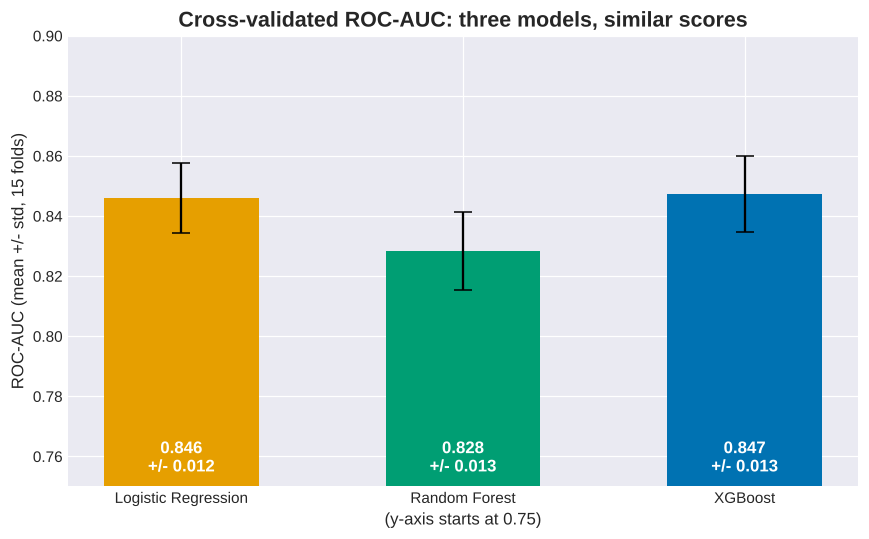

In [6]:
names = list(cv_out)
means = [cv_out[n]["test_roc_auc"].mean() for n in names]
stds = [cv_out[n]["test_roc_auc"].std() for n in names]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(names, means, yerr=stds, capsize=6, color=[GOLD, GREEN, BLUE], width=0.55)
for bar, m, s in zip(bars, means, stds):
    ax.text(bar.get_x() + bar.get_width() / 2, 0.755, f"{m:.3f}\n+/- {s:.3f}", ha="center",
            color="white", fontweight="bold", fontsize=11)
ax.set_ylim(0.75, 0.90)
ax.set_title("Cross-validated ROC-AUC: three models, similar scores")
ax.set_ylabel("ROC-AUC (mean +/- std, 15 folds)")
ax.set_xlabel("(y-axis starts at 0.75)")
plt.tight_layout()
plt.savefig("images/model_comparison_auc.png")
plt.show()

### Is the ranking real, or noise? (paired, fold by fold)

In [7]:
order = sorted(names, key=lambda n: cv_out[n]["test_roc_auc"].mean(), reverse=True)
first, second = order[0], order[1]
diff = cv_out[first]["test_roc_auc"] - cv_out[second]["test_roc_auc"]

print("Top two by mean ROC-AUC:", first, "and", second)
print(f"Mean difference {diff.mean():+.4f} | std of differences {diff.std():.4f}")
print(f"{first} is better in {int((diff > 0).sum())} of {len(diff)} folds")

Top two by mean ROC-AUC: XGBoost and Logistic Regression
Mean difference +0.0015 | std of differences 0.0035
XGBoost is better in 11 of 15 folds


## 3. ROC curves for all three models on one chart

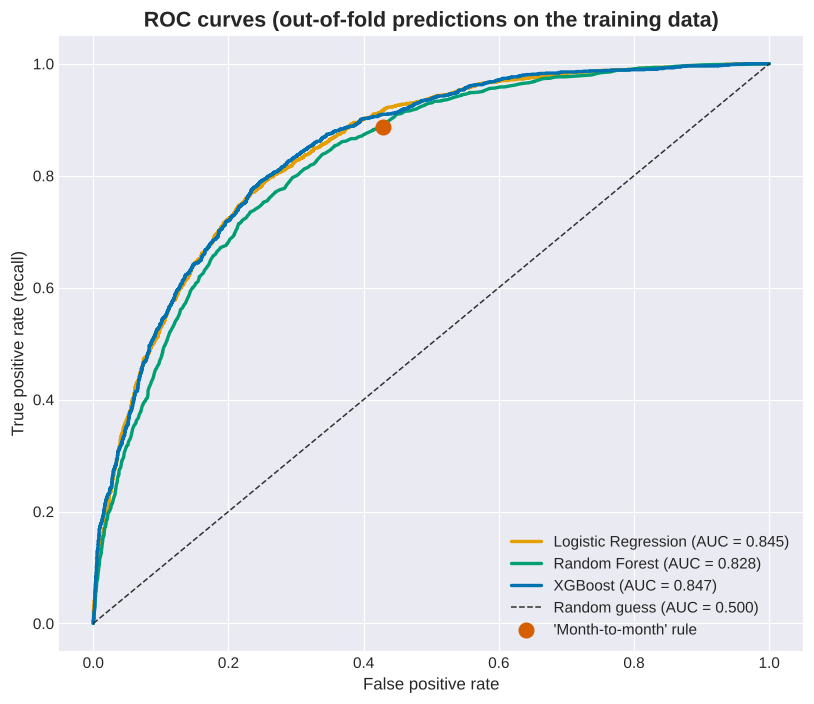

Logistic Regression  pooled out-of-fold AUC 0.845
Random Forest        pooled out-of-fold AUC 0.828
XGBoost              pooled out-of-fold AUC 0.847
'Month-to-month' rule: recall 0.887 at false positive rate 0.429


In [8]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=42)
oof = {name: cross_val_predict(pipe, X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
       for name, pipe in pipes.items()}

# The simple Day 80 rule, a single point on the chart: 'month-to-month means churn'
rule = (X_train["Contract"] == "Month-to-month").astype(int)
rule_tpr = recall_score(y_train, rule)
rule_fpr = ((rule == 1) & (y_train == 0)).sum() / (y_train == 0).sum()

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for (name, p), color in zip(oof.items(), [GOLD, GREEN, BLUE]):
    fpr, tpr, _ = roc_curve(y_train, p)
    ax.plot(fpr, tpr, color=color, linewidth=2.2, label=f"{name} (AUC = {roc_auc_score(y_train, p):.3f})")
ax.plot([0, 1], [0, 1], color="#333333", linestyle="--", linewidth=1, label="Random guess (AUC = 0.500)")
ax.scatter([rule_fpr], [rule_tpr], s=90, color=ORANGE, zorder=5, label="'Month-to-month' rule")
ax.set_title("ROC curves (out-of-fold predictions on the training data)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/roc_curves_three_models.png")
plt.show()

for name, p in oof.items():
    print(f"{name:20s} pooled out-of-fold AUC {roc_auc_score(y_train, p):.3f}")
print(f"'Month-to-month' rule: recall {rule_tpr:.3f} at false positive rate {rule_fpr:.3f}")

## 4. Tune the best model with `GridSearchCV` (training data only)
The best model is picked by code, using rule 1: the highest mean cross-validated ROC-AUC.

In [9]:
grids = {
    "Logistic Regression": {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    "Random Forest": {"model__max_depth": [4, 6, 8, None], "model__min_samples_leaf": [1, 5, 10],
                      "model__max_features": ["sqrt", 0.3]},
    "XGBoost": {"model__n_estimators": [100, 200, 400], "model__learning_rate": [0.03, 0.05, 0.1],
                "model__max_depth": [2, 3, 4]},
}
best_name = order[0]
print("Best model by cross-validated ROC-AUC:", best_name)
print("Grid:", grids[best_name])

gs = GridSearchCV(pipes[best_name], grids[best_name], scoring="roc_auc", cv=cv5, n_jobs=1)
gs.fit(X_train, y_train)
print("Settings tried:", len(gs.cv_results_["params"]), "x 5 folds")

Best model by cross-validated ROC-AUC: XGBoost
Grid: {'model__n_estimators': [100, 200, 400], 'model__learning_rate': [0.03, 0.05, 0.1], 'model__max_depth': [2, 3, 4]}


Settings tried: 27 x 5 folds


In [10]:
default_auc = cross_validate(pipes[best_name], X_train, y_train, cv=cv5, scoring="roc_auc")["test_score"].mean()
print("Best settings:", {k.replace("model__", ""): v for k, v in gs.best_params_.items()})
print(f"CV ROC-AUC with the starting settings: {default_auc:.3f}")
print(f"CV ROC-AUC with the best settings:     {gs.best_score_:.3f} (optimistic: best of {len(gs.cv_results_['params'])} tries)")

Best settings: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
CV ROC-AUC with the starting settings: 0.847
CV ROC-AUC with the best settings:     0.849 (optimistic: best of 27 tries)


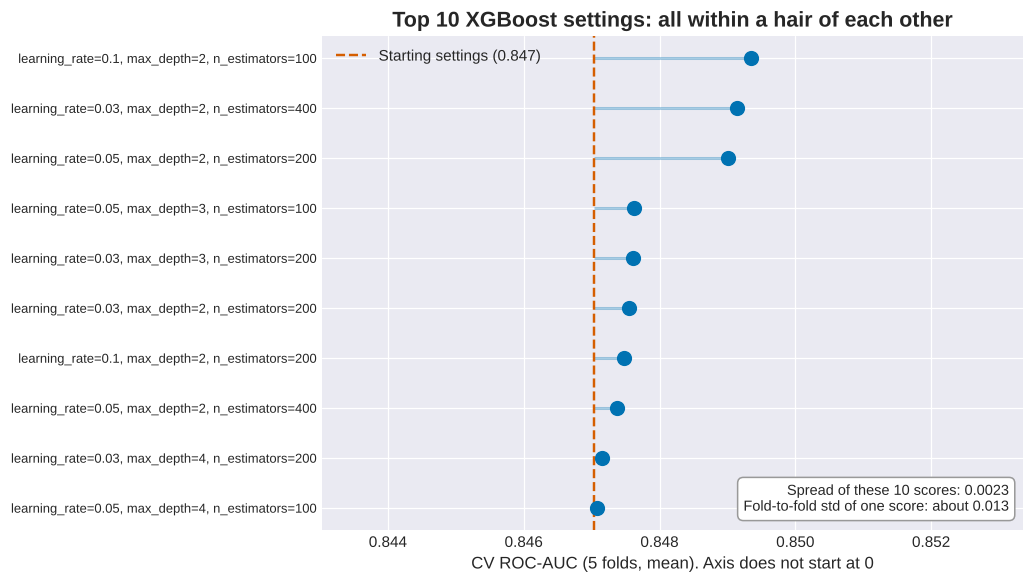

In [11]:
res = pd.DataFrame(gs.cv_results_).sort_values("mean_test_score", ascending=False).head(10).iloc[::-1]
labels = [", ".join(f"{k.replace('model__', '')}={v}" for k, v in p.items()) for p in res["params"]]

fig, ax = plt.subplots(figsize=(9.5, 5.4))
scores = res["mean_test_score"].to_numpy()
ax.hlines(range(len(res)), default_auc, scores, color=BLUE, alpha=0.35, linewidth=2)
ax.scatter(scores, range(len(res)), color=BLUE, s=80, zorder=3)
ax.axvline(default_auc, color=ORANGE, linestyle="--", linewidth=1.6, label=f"Starting settings ({default_auc:.3f})")
ax.set_yticks(range(len(res)))
ax.set_yticklabels(labels, fontsize=8.5)
ax.set_xlim(default_auc - 0.004, scores.max() + 0.004)
ax.set_title(f"Top 10 {best_name} settings: all within a hair of each other")
ax.set_xlabel("CV ROC-AUC (5 folds, mean). Axis does not start at 0")
spread = scores.max() - scores.min()
ax.text(0.98, 0.04, f"Spread of these 10 scores: {spread:.4f}\nFold-to-fold std of one score: about {res['std_test_score'].mean():.3f}",
        transform=ax.transAxes, ha="right", fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#999999"))
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("images/grid_search_top10.png")
plt.show()

## 5. The final check on the hold-out test set (looked at once)
Rules 2 and 3: the model and its settings are frozen. This cell only reports.

In [12]:
final = gs.best_estimator_
start = pipes[best_name].fit(X_train, y_train)

p_final = final.predict_proba(X_test)[:, 1]
p_start = start.predict_proba(X_test)[:, 1]

print(f"{best_name}, starting settings:  test ROC-AUC {roc_auc_score(y_test, p_start):.3f}")
print(f"{best_name}, tuned settings:     test ROC-AUC {roc_auc_score(y_test, p_final):.3f}"
      f" | PR-AUC {average_precision_score(y_test, p_final):.3f}")

rng = np.random.default_rng(42)
y_arr = y_test.to_numpy()
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    boot.append(roc_auc_score(y_arr[idx], p_final[idx]))
low, high = np.percentile(boot, [2.5, 97.5])
print(f"Bootstrap 95% interval for the tuned test ROC-AUC: {low:.3f} to {high:.3f}")
print("For context, cross-validated ROC-AUC of the tuned settings (training data):", round(gs.best_score_, 3))

XGBoost, starting settings:  test ROC-AUC 0.843
XGBoost, tuned settings:     test ROC-AUC 0.846 | PR-AUC 0.660


Bootstrap 95% interval for the tuned test ROC-AUC: 0.823 to 0.867
For context, cross-validated ROC-AUC of the tuned settings (training data): 0.849


Logistic Regression  untuned test ROC-AUC 0.842


Random Forest        untuned test ROC-AUC 0.827


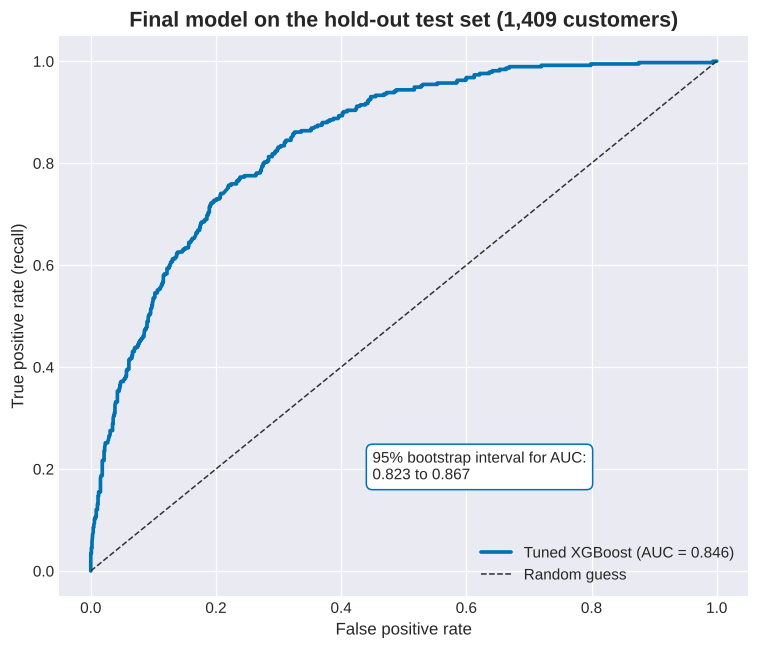

In [13]:
# For context only (not used to choose anything): the other models, untuned, on the same test set
for name, pipe in pipes.items():
    if name != best_name:
        p = pipe.fit(X_train, y_train).predict_proba(X_test)[:, 1]
        print(f"{name:20s} untuned test ROC-AUC {roc_auc_score(y_test, p):.3f}")

fpr, tpr, _ = roc_curve(y_test, p_final)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color=BLUE, linewidth=2.4, label=f"Tuned {best_name} (AUC = {roc_auc_score(y_test, p_final):.3f})")
ax.plot([0, 1], [0, 1], color="#333333", linestyle="--", linewidth=1, label="Random guess")
ax.text(0.45, 0.18, f"95% bootstrap interval for AUC:\n{low:.3f} to {high:.3f}", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=BLUE))
ax.set_title("Final model on the hold-out test set (1,409 customers)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/final_model_test_roc.png")
plt.show()

## Practice Exercise
Which of the three models overfits most? Compare training ROC-AUC with cross-validated ROC-AUC.

In [14]:
for name, pipe in pipes.items():
    out = cross_validate(pipe, X_train, y_train, cv=cv5, scoring="roc_auc", return_train_score=True)
    tr, te = out["train_score"].mean(), out["test_score"].mean()
    print(f"{name:20s} train {tr:.3f} | CV {te:.3f} | gap {tr - te:.3f}")

Logistic Regression  train 0.849 | CV 0.846 | gap 0.004


Random Forest        train 1.000 | CV 0.828 | gap 0.172


XGBoost              train 0.879 | CV 0.847 | gap 0.031


## Mini Challenge
Does `class_weight="balanced"` change Logistic Regression's ROC-AUC? (Day 81 suggested weights shift the balance, not the ranking.)

In [15]:
plain = build_model_pipeline(LogisticRegression(max_iter=2000))
auc_plain = cross_validate(plain, X_train, y_train, cv=rcv, scoring="roc_auc")["test_score"]
auc_bal = cv_out["Logistic Regression"]["test_roc_auc"]
print(f"No class weights: ROC-AUC {auc_plain.mean():.4f} | balanced: {auc_bal.mean():.4f}")
print(f"Mean paired difference {(auc_bal - auc_plain).mean():+.5f} over {len(auc_bal)} folds")

No class weights: ROC-AUC 0.8461 | balanced: 0.8459
Mean paired difference -0.00016 over 15 folds


## Summary
- Three models in identical pipelines, compared with the same 15 cross-validation folds
- The best model was chosen by code, using cross-validated ROC-AUC only
- Tuning with `GridSearchCV` on the training data changed the score very little
- The test set was used once, at the end, with a bootstrap interval for the AUC
- Next: Day 83, confusion matrix, business threshold, and insights